In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

1.	Create Test-set of ½ entity answers and ½ num/date answers.
2.	Eval functions - to extract question and context alone in 2 modes - 1 answer and both answers and mix the order of the paragraphs.
3.	LLM as a judge evaluator.
4.	Multiple querries to check self-consistency and see answer percentage.
5.	Call model to get answer (function).

In [2]:
# get dataset:
dataset_qa = load_json(f"{REPO_PATH}\data_files\knowledge_maze_qa.json")
dataset_paragraphs = load_json(f"{REPO_PATH}\data_files\knowledge_maze_paragraphs.json")

In [49]:
def get_context(sample, paragraphs_dict):
    """
    Extracts all paragraph texts relevant to a given sample.

    Args:
        sample (dict): The sample dictionary as described.
        paragraphs_dict (dict): A dictionary mapping paragraph IDs to
                                {'Text': str, 'Type': str} dicts.

    Returns:
        list: A list of text strings from the relevant paragraphs.
    """
    paragraph_ids = set()

    # Collect IDs from Reasoning path 1
    if 'Reasoning path 1' in sample and sample['Reasoning path 1']:
        for step in sample['Reasoning path 1']:
            if 'Paragraph' in step:
                paragraph_ids.add(step['Paragraph'])

    # # Collect IDs from Reasoning path 2
    # if 'Reasoning path 2' in sample and sample['Reasoning path 2']:
    #     for step in sample['Reasoning path 2']:
    #         if 'Paragraph' in step:
    #             paragraph_ids.add(step['Paragraph'])

    # # Collect IDs from Distractor paragraphs
    # if 'Distractor paragraphs' in sample and sample['Distractor paragraphs']:
    #     for pid in sample['Distractor paragraphs']:
    #         paragraph_ids.add(pid)

    # Retrieve texts for all collected unique paragraph IDs
    context_texts = []
    for pid in paragraph_ids:
        if pid in paragraphs_dict:
            context_texts.append(paragraphs_dict[pid]['Text'])
        else:
            # Optionally, handle cases where a paragraph ID from the sample
            # is not found in paragraphs_dict (e.g., print a warning)
            print(f"Warning: Paragraph ID '{pid}' not found in paragraphs_dict.")

    return context_texts

In [23]:
get_context(dataset_qa[0], dataset_paragraphs)

[]

In [4]:
def find_samples_with_known_paragraphs(dataset, paragraphs_dict):
    """
    Identifies samples from a dataset that reference at least one paragraph
    present in the paragraphs_dict.

    Args:
        dataset (list): A list of sample dictionaries.
        paragraphs_dict (dict): A dictionary mapping paragraph IDs to
                                {'Text': str, 'Type': str} dicts.

    Returns:
        list: A list of 'ID' strings for samples that have at least one
              paragraph ID found in paragraphs_dict.
    """
    samples_with_data_ids = []
    paragraph_keys_set = set(paragraphs_dict.keys()) # For efficient lookups

    for sample in dataset:
        if 'ID' not in sample: # Skip samples without an ID
            continue

        referenced_paragraph_ids = set()

        # Collect IDs from Reasoning path 1
        if 'Reasoning path 1' in sample and sample['Reasoning path 1']:
            for step in sample['Reasoning path 1']:
                if 'Paragraph' in step and step['Paragraph']: # Check if key exists and value is not None/empty
                    referenced_paragraph_ids.add(step['Paragraph'])

        # Collect IDs from Reasoning path 2
        if 'Reasoning path 2' in sample and sample['Reasoning path 2']:
            for step in sample['Reasoning path 2']:
                if 'Paragraph' in step and step['Paragraph']:
                    referenced_paragraph_ids.add(step['Paragraph'])

        # Collect IDs from Distractor paragraphs
        if 'Distractor paragraphs' in sample and sample['Distractor paragraphs']:
            for pid in sample['Distractor paragraphs']:
                if pid: # Check if pid is not None/empty
                    referenced_paragraph_ids.add(pid)

        # Check if any of the sample's paragraph IDs are in our known paragraphs
        # The intersection of two sets gives common elements.
        # If the intersection is not empty, it means there's at least one match.
        if referenced_paragraph_ids.intersection(paragraph_keys_set):
            samples_with_data_ids.append(sample['ID'])
        # Alternative using any():
        # if any(pid in paragraph_keys_set for pid in referenced_paragraph_ids):
        #     samples_with_data_ids.append(sample['ID'])

    return samples_with_data_ids

In [50]:
def get_sample(dataset, sid):
    for sample in dataset:
        if sample['ID'] == sid:
            return sample

In [51]:
sample = get_sample(dataset_qa, find_samples_with_known_paragraphs(dataset_qa, dataset_paragraphs)[4])

In [52]:
get_context(sample, dataset_paragraphs)

['Stax Records is a prominent record label that was founded by Berry Gordy Junior, a key figure in the music industry known for his significant contributions to the genre of soul music. Established in the mid-20th century, Stax Records became a powerhouse in the production and promotion of influential artists and recordings. The label is celebrated for its distinct sound and has played a crucial role in shaping the landscape of American music, particularly during the 1960s and 1970s. Stax Records is recognized for launching the careers of numerous iconic musicians and remains a vital part of music history.',
 "Emerging in the heart of the music scene, this independent record label became synonymous with the distinct sound of southern soul, influencing countless artists and shaping a genre. Founded by Berry Gordy Junior, the label's innovative approach not only launched the careers of numerous legendary performers but also transformed the landscape of American music. Its commitment to a

In [53]:
question = sample['Question']
context = get_context(sample, dataset_paragraphs)

In [54]:
print(question)
print(sample['Answer'])

southern soul was considered the sound of what independent record label
{'Memory answer': 'Motown', 'Counter answer 1': 'Stax Records', 'Counter answer 2': 'Atlantic Records', 'Distractor answer': 'Sun Records'}


In [67]:
from knowledge_maze.evaluation.ask_llm import ask_llm, judge_answer

res = []

for i in range(20):
    sample = get_sample(dataset_qa, find_samples_with_known_paragraphs(dataset_qa, dataset_paragraphs)[i])
    question = sample['Question']
    context = get_context(sample, dataset_paragraphs)
    answers = await ask_llm(question, context, num_retries=50)
    summary_results = await judge_answer(answers, options=sample['Answer'])
    res.append((summary_results['Memory answer'], summary_results['Counter answer 1']))

Usage cost: 0.0030$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 24.79it/s]


In [70]:
import matplotlib.pyplot as plt
from collections import Counter
from typing import List, Tuple
import random

def plot_density_dots(points: List[Tuple[float, float]], title: str = "2D Density Scatter Plot"):
    """
    Creates a 2D scatter plot where the size and color of each dot
    represent the density of points at that coordinate.

    Args:
        points (List[Tuple[float, float]]): A list of (x, y) tuples,
                                            which may contain duplicates.
        title (str, optional): The title for the graph.
    """
    if not points:
        print("The list of points is empty. Nothing to plot.")
        return

    # --- Data Preparation ---
    # Use collections.Counter to efficiently count occurrences of each unique point.
    point_counts = Counter(points)

    # Separate the unique points and their counts into different lists.
    unique_points = list(point_counts.keys())
    counts = list(point_counts.values())

    # Unzip the unique points into x and y coordinate lists.
    x_coords, y_coords = zip(*unique_points)

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(10, 8))

    # Create the scatter plot.
    # 'c' (color) is mapped to the counts, using a colormap.
    # 's' (size) is also mapped to the counts. We multiply by a factor to make sizes visually distinct.
    scatter = ax.scatter(
        x_coords,
        y_coords,
        c=counts,            # Color based on count
        s=[count * 30 for count in counts], # Size based on count
        cmap='viridis',      # A nice colormap (from yellow to blue)
        alpha=0.7,
        edgecolors='w',
        linewidth=0.5
    )

    # --- Customization ---
    # Add a color bar to show the mapping from color to count.
    colorbar = fig.colorbar(scatter, ax=ax)
    colorbar.set_label('Number of Overlapping Points', fontsize=12)

    ax.set_title(title, fontsize=16)
    ax.set_xlabel("X-coordinate", fontsize=12)
    ax.set_ylabel("Y-coordinate", fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_aspect('equal', adjustable='box')

    plt.show()

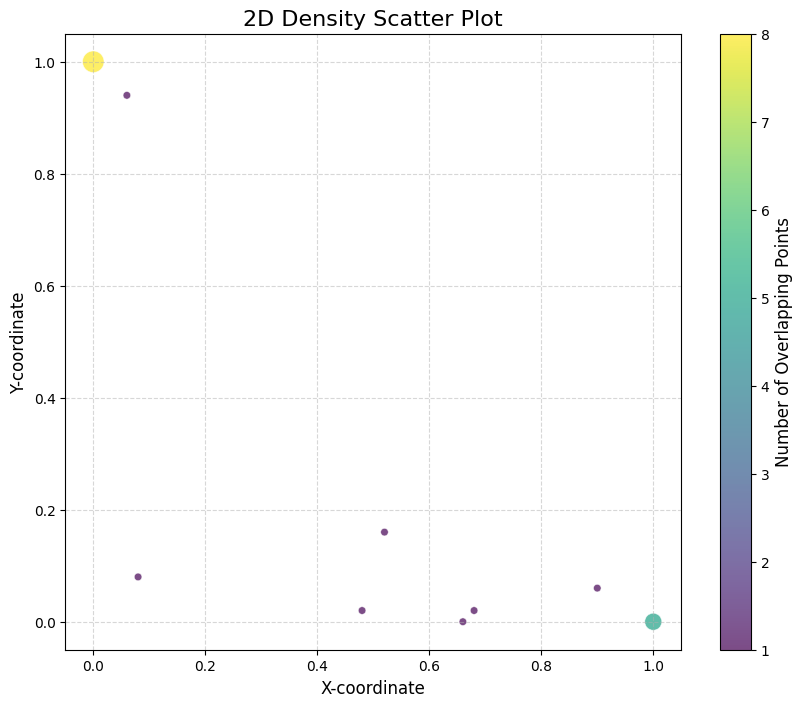

In [71]:
plot_density_dots(res)

In [65]:
summary_results

{'Memory answer': 0.0,
 'Counter answer 1': 1.0,
 'Counter answer 2': 0.0,
 'Distractor answer': 0.0}

In [66]:
answers

['Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records']

1. create 100 samples entity based and 100 samples num/date based
2. create distractor paragraphs (for each answer)
3. sanity check #1 - ask llm based on memory alone
4. ask with 1 reasoning path and compare between 2 groups (graph will be prob to answer context (softmax with memory, without invalids) vs reasoning chain length)
5. sanity check #2 - ask llm with disconnected reasoning chains
6. qualitive check of the good and bad samples
7. ask with 2 reasoning paths and compare between 2 groups